## Задание 3.4 Torch: Свёрточные сети (CNN)


In [19]:
import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim

In [21]:
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid

In [22]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns


In [23]:
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch version: 2.11.0
CUDA available: False


### фиксируем seed и устройство

In [24]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

### классы CIFAR-10

In [40]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

### Трансформации

Без аугментации: ToTensor + Normalize

In [41]:
train_tfms_plain = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar10_mean, cifar10_std)
])

С аугментацией

In [42]:
train_tfms_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),       # случайный сдвиг кадра
    transforms.RandomHorizontalFlip(),          # отражение
    transforms.RandomRotation(15),              # поворот
    transforms.ToTensor(),
    transforms.Normalize(cifar10_mean, cifar10_std)
])

Для теста/валидации аугментация не нужна

In [43]:
test_tfms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar10_mean, cifar10_std)
])

### Загрузка датасета

In [45]:
data_root = "./data"

In [46]:
train_dataset_aug = datasets.CIFAR10(
    root=data_root,
    train=True,
    download=True,
    transform=train_tfms_aug
)

In [47]:
train_dataset_plain = datasets.CIFAR10(
    root=data_root,
    train=True,
    download=True,
    transform=train_tfms_plain
)

In [48]:
test_dataset = datasets.CIFAR10(
    root=data_root,
    train=False,
    download=True,
    transform=test_tfms
)

In [49]:
len(train_dataset_aug), len(test_dataset)

(50000, 10000)

### Разделение на train/val

In [50]:
val_size = 5000
train_size = len(train_dataset_aug) - val_size

In [51]:
train_subset_aug, val_subset = random_split(
    train_dataset_aug,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)


Для честного сравнения без аугментации нужен отдельный train subset с теми же индексами

In [ ]:
indices = train_subset_aug.indices
train_subset_plain = torch.utils.data.Subset(train_dataset_plain, indices)


In [53]:
len(train_subset_aug), len(val_subset), len(train_subset_plain)

(45000, 5000, 45000)

### DataLoader

In [58]:
batch_size = 128

In [59]:
train_loader_aug = DataLoader(
    train_subset_aug, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=True
)

In [60]:
train_loader_plain = DataLoader(
    train_subset_plain, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=True
)


In [61]:
val_loader = DataLoader(
    val_subset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=True
)

In [62]:
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=True
)

### Вспомогательные функции для визуализации

In [63]:
def denormalize(tensor, mean=cifar10_mean, std=cifar10_std):
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return tensor * std + mean

In [64]:
def show_images(images, labels=None, n=16, title=None):
    images = images[:n]
    if images.dim() == 4:
        grid = make_grid(images, nrow=4)
    else:
        grid = images

    grid = denormalize(grid).clamp(0, 1)

    plt.figure(figsize=(10, 10))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()

### как выглядит датасет

In [67]:
preview_dataset = datasets.CIFAR10(
    root=data_root,
    train=True,
    download=False,
    transform=transforms.ToTensor()
)

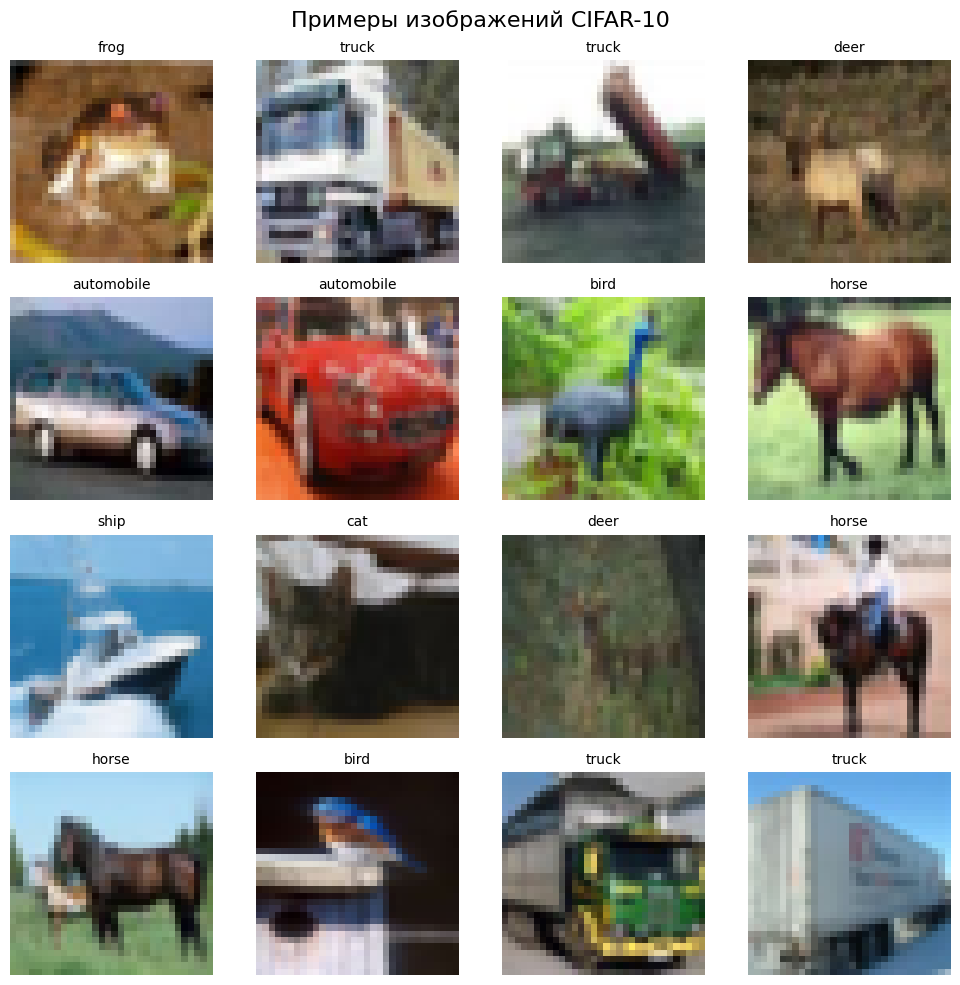

In [68]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    img, label = preview_dataset[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(class_names[label], fontsize=10)
    ax.axis("off")
plt.suptitle("Примеры изображений CIFAR-10", fontsize=16)
plt.tight_layout()
plt.show()

### Пример аугментации одного и того же изображения

In [69]:
sample_img, sample_label = datasets.CIFAR10(
    root=data_root,
    train=True,
    download=False,
    transform=None
)[0]

In [70]:
augment_preview = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor()
])

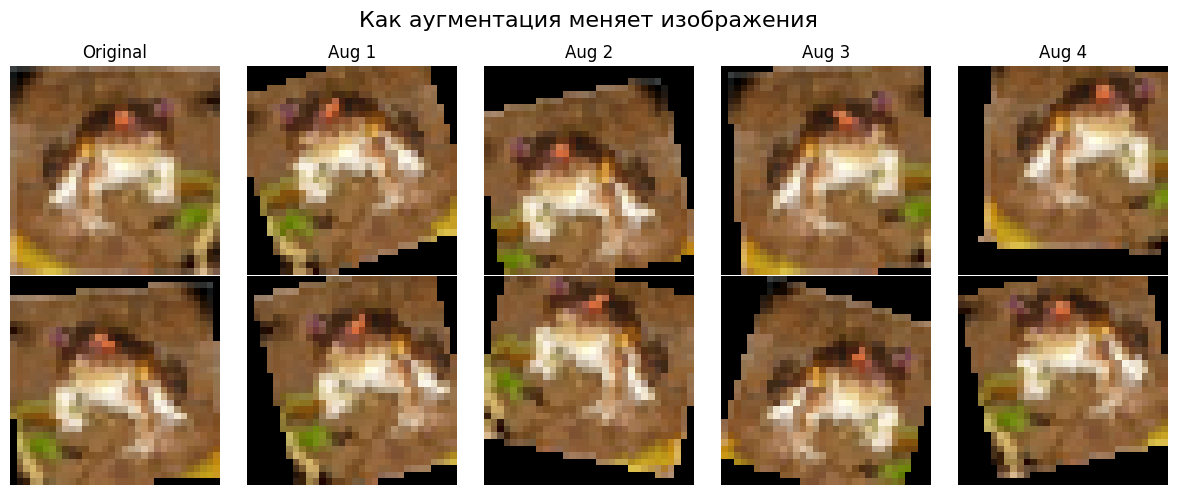

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# оригинал
axes[0, 0].imshow(sample_img)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

# аугментированные версии
for i in range(1, 5):
    aug_img = augment_preview(sample_img)
    axes[0, i].imshow(aug_img.permute(1, 2, 0))
    axes[0, i].set_title(f"Aug {i}")
    axes[0, i].axis("off")

# ещё варианты
for i in range(5):
    aug_img = augment_preview(sample_img)
    axes[1, i].imshow(aug_img.permute(1, 2, 0))
    axes[1, i].axis("off")

plt.suptitle("Как аугментация меняет изображения", fontsize=16)
plt.tight_layout()
plt.show()

## 3 архитектуры CNN

In [72]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 -> 16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16 -> 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [73]:
class MediumCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 -> 16

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16 -> 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [74]:
class DeepCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 -> 16

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16 -> 8

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### early stopping

Если модель долго не улучшается, то останавливаем обучение

patience — сколько эпох ждать улучшения     
min_delta — минимальное улучшение, чтобы считать его значимым           

In [ ]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf") 
        self.counter = 0
        self.best_state = None
        self.best_epoch = 0

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_state = copy.deepcopy(model.state_dict())
            self.counter = 0
            self.best_epoch = epoch
            return False
        else:
            self.counter += 1
            return self.counter >= self.patience

### Обучение и оценка

In [ ]:
def accuracy_from_logits(logits, y_true):
    preds = torch.argmax(logits, dim=1)
    return (preds == y_true).float().mean().item()

In [77]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    total_acc = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total_acc += (torch.argmax(logits, dim=1) == y).sum().item()

    return total_loss / len(loader.dataset), total_acc / len(loader.dataset)

In [78]:

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    total_acc = 0

    all_preds = []
    all_targets = []

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        preds = torch.argmax(logits, dim=1)

        total_loss += loss.item() * x.size(0)
        total_acc += (preds == y).sum().item()

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y.cpu().numpy())

    return total_loss / len(loader.dataset), total_acc / len(loader.dataset), np.array(all_preds), np.array(all_targets)

### Общий цикл обучения

In [ ]:
def fit_model(model, train_loader, val_loader, epochs=30, lr=1e-3, patience=5, device=device):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    early_stopper = EarlyStopping(patience=patience)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch:02d} | "
            f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | "
            f"Val loss: {val_loss:.4f}, acc: {val_acc:.4f}"
        )

        if early_stopper.step(val_loss, model, epoch):
            print(f"Early stopping on epoch {epoch}. Best epoch: {early_stopper.best_epoch}")
            break

    if early_stopper.best_state is not None:
        model.load_state_dict(early_stopper.best_state)

    return model, history

In [80]:
def plot_history(history, title="Training history"):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, history["train_loss"], label="Train loss")
    axes[0].plot(epochs, history["val_loss"], label="Val loss")
    axes[0].set_title(f"{title} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train acc")
    axes[1].plot(epochs, history["val_acc"], label="Val acc")
    axes[1].set_title(f"{title} — Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### Сравнение с аугментацией и без неё

In [81]:
model_plain = MediumCNN()
model_aug = MediumCNN()

In [82]:
print("Training without augmentation...")
model_plain, history_plain = fit_model(
    model_plain,
    train_loader_plain,
    val_loader,
    epochs=25,
    lr=1e-3,
    patience=5
)


Training without augmentation...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch 01 | Train loss: 1.4951, acc: 0.4527 | Val loss: 1.8814, acc: 0.3472
Epoch 02 | Train loss: 1.0947, acc: 0.6158 | Val loss: 1.6455, acc: 0.4312
Epoch 03 | Train loss: 0.9639, acc: 0.6642 | Val loss: 1.6417, acc: 0.4308
Epoch 04 | Train loss: 0.8712, acc: 0.6987 | Val loss: 1.6076, acc: 0.4490
Epoch 05 | Train loss: 0.8033, acc: 0.7210 | Val loss: 1.6228, acc: 0.4498
Epoch 06 | Train loss: 0.7496, acc: 0.7407 | Val loss: 1.5720, acc: 0.4776
Epoch 07 | Train loss: 0.7004, acc: 0.7586 | Val loss: 1.5128, acc: 0.4826
Epoch 08 | Train loss: 0.6595, acc: 0.7698 | Val loss: 1.6740, acc: 0.4646
Epoch 09 | Train loss: 0.6207, acc: 0.7852 | Val loss: 1.7381, acc: 0.4734
Epoch 10 | Train loss: 0.5845, acc: 0.7982 | Val loss: 1.6454, acc: 0.4840
Epoch 11 | Train loss: 0.5478, acc: 0.8089 | Val loss: 1.6777, acc: 0.4854
Epoch 12 | Train loss: 0.5106, acc: 0.8198 | Val loss: 2.0622, acc: 0.4548
Early stopping on epoch 12. Best epoch: 7


In [83]:
print("\nTraining with augmentation...")
model_aug, history_aug = fit_model(
    model_aug,
    train_loader_aug,
    val_loader,
    epochs=25,
    lr=1e-3,
    patience=5
)


Training with augmentation...
Epoch 01 | Train loss: 1.7484, acc: 0.3440 | Val loss: 1.4264, acc: 0.4692
Epoch 02 | Train loss: 1.4783, acc: 0.4570 | Val loss: 1.3678, acc: 0.5026
Epoch 03 | Train loss: 1.3563, acc: 0.5078 | Val loss: 1.2371, acc: 0.5468
Epoch 04 | Train loss: 1.2731, acc: 0.5422 | Val loss: 1.1601, acc: 0.5808
Epoch 05 | Train loss: 1.2136, acc: 0.5661 | Val loss: 1.1543, acc: 0.5934
Epoch 06 | Train loss: 1.1633, acc: 0.5860 | Val loss: 1.0477, acc: 0.6318
Epoch 07 | Train loss: 1.1278, acc: 0.5995 | Val loss: 1.0338, acc: 0.6454
Epoch 08 | Train loss: 1.0979, acc: 0.6102 | Val loss: 0.9814, acc: 0.6606
Epoch 09 | Train loss: 1.0726, acc: 0.6214 | Val loss: 1.0151, acc: 0.6516
Epoch 10 | Train loss: 1.0519, acc: 0.6320 | Val loss: 0.9549, acc: 0.6670
Epoch 11 | Train loss: 1.0334, acc: 0.6377 | Val loss: 0.9321, acc: 0.6696
Epoch 12 | Train loss: 1.0141, acc: 0.6456 | Val loss: 0.9292, acc: 0.6754
Epoch 13 | Train loss: 0.9905, acc: 0.6510 | Val loss: 0.9138, acc: 0

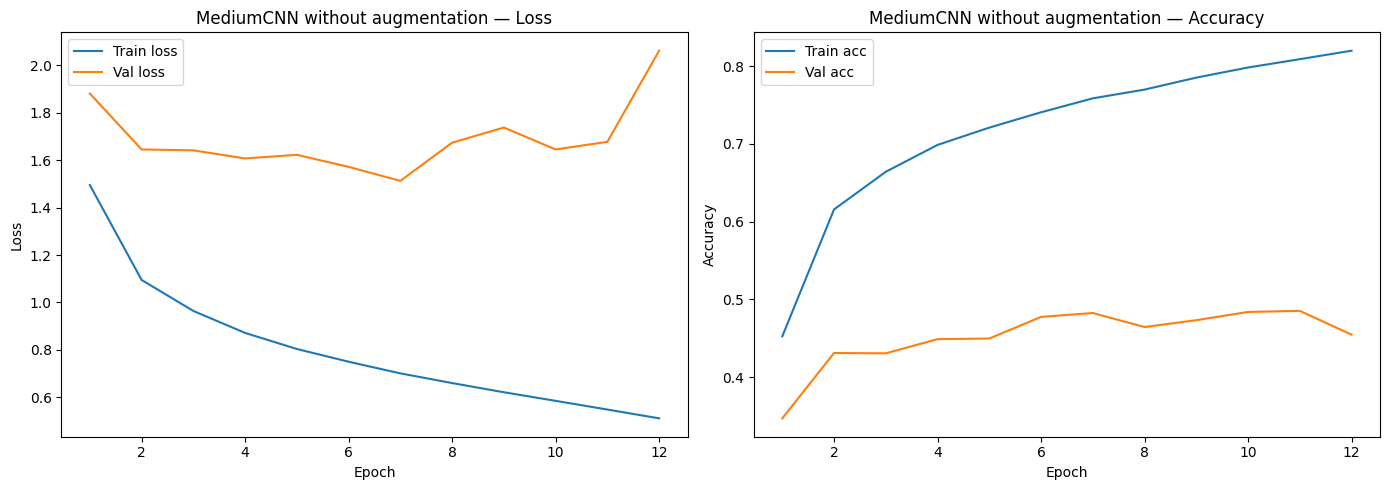

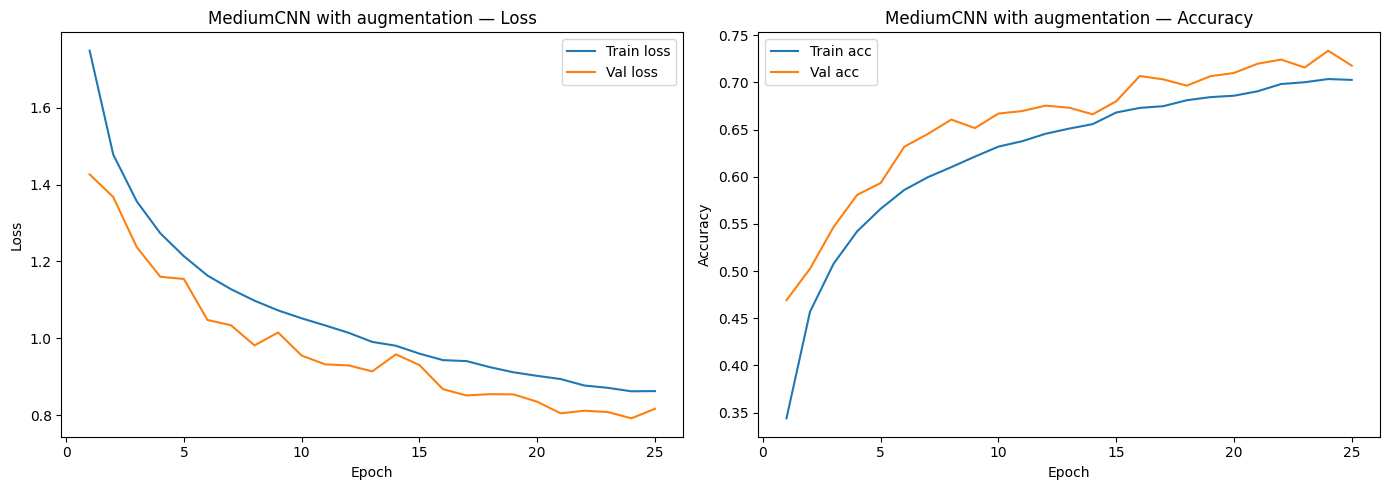

In [84]:
plot_history(history_plain, title="MediumCNN without augmentation")
plot_history(history_aug, title="MediumCNN with augmentation")

#### сравнение на тесте

In [85]:
criterion = nn.CrossEntropyLoss()


In [86]:
plain_test_loss, plain_test_acc, plain_preds, plain_targets = evaluate(model_plain, test_loader, criterion, device)
aug_test_loss, aug_test_acc, aug_preds, aug_targets = evaluate(model_aug, test_loader, criterion, device)


In [87]:
print(f"Without augmentation -> test loss: {plain_test_loss:.4f}, test acc: {plain_test_acc:.4f}")
print(f"With augmentation    -> test loss: {aug_test_loss:.4f}, test acc: {aug_test_acc:.4f}")

Without augmentation -> test loss: 0.7181, test acc: 0.7530
With augmentation    -> test loss: 0.6690, test acc: 0.7697


### Сравнение 3 архитектур

In [88]:
models = {
    "SimpleCNN": SimpleCNN(),
    "MediumCNN": MediumCNN(),
    "DeepCNN": DeepCNN()
}

In [89]:
trained_models = {}
histories = {}
results = []

In [90]:
for name, model in models.items():
    print(f"\nTraining {name}")
    trained_model, history = fit_model(
        model,
        train_loader_aug,
        val_loader,
        epochs=30,
        lr=1e-3,
        patience=5
    )
    trained_models[name] = trained_model
    histories[name] = history

    test_loss, test_acc, preds, targets = evaluate(trained_model, test_loader, criterion, device)
    results.append({
        "model": name,
        "test_loss": test_loss,
        "test_acc": test_acc
    })

results


Training SimpleCNN
Epoch 01 | Train loss: 1.7176, acc: 0.3624 | Val loss: 1.5179, acc: 0.4468
Epoch 02 | Train loss: 1.5149, acc: 0.4420 | Val loss: 1.3962, acc: 0.4822
Epoch 03 | Train loss: 1.4182, acc: 0.4808 | Val loss: 1.2874, acc: 0.5318
Epoch 04 | Train loss: 1.3616, acc: 0.5022 | Val loss: 1.2427, acc: 0.5610
Epoch 05 | Train loss: 1.3163, acc: 0.5244 | Val loss: 1.1725, acc: 0.5888
Epoch 06 | Train loss: 1.2890, acc: 0.5332 | Val loss: 1.1820, acc: 0.5686
Epoch 07 | Train loss: 1.2566, acc: 0.5464 | Val loss: 1.1866, acc: 0.5738
Epoch 08 | Train loss: 1.2299, acc: 0.5560 | Val loss: 1.1118, acc: 0.5950
Epoch 09 | Train loss: 1.2124, acc: 0.5610 | Val loss: 1.1636, acc: 0.5812
Epoch 10 | Train loss: 1.2026, acc: 0.5669 | Val loss: 1.1330, acc: 0.5932
Epoch 11 | Train loss: 1.1911, acc: 0.5738 | Val loss: 1.0639, acc: 0.6176
Epoch 12 | Train loss: 1.1731, acc: 0.5788 | Val loss: 1.0523, acc: 0.6282
Epoch 13 | Train loss: 1.1602, acc: 0.5856 | Val loss: 1.0482, acc: 0.6210
Epoch

[{'model': 'SimpleCNN', 'test_loss': 0.7739596755027771, 'test_acc': 0.7358},
 {'model': 'MediumCNN', 'test_loss': 0.6449780740737915, 'test_acc': 0.7756},
 {'model': 'DeepCNN', 'test_loss': 0.4874567944049835, 'test_acc': 0.8366}]

In [91]:
import pandas as pd

Таблица результатов

In [92]:
results_df = pd.DataFrame(results).sort_values(by="test_acc", ascending=False)
results_df

,model,test_loss,test_acc
2,DeepCNN,0.487457,0.8366
1,MediumCNN,0.644978,0.7756
0,SimpleCNN,0.773960,0.7358


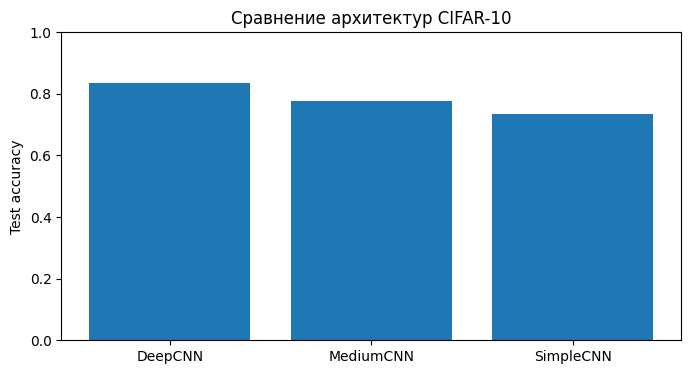

In [93]:
plt.figure(figsize=(8, 4))
plt.bar(results_df["model"], results_df["test_acc"])
plt.ylabel("Test accuracy")
plt.title("Сравнение архитектур CIFAR-10")
plt.ylim(0, 1)
plt.show()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


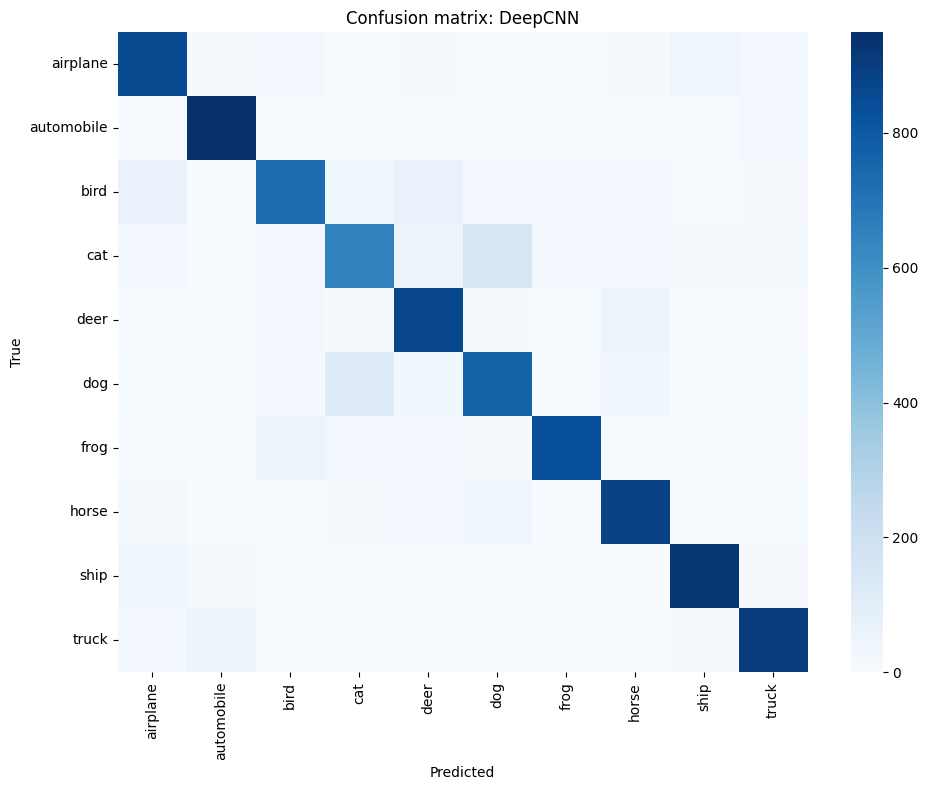

In [94]:
def plot_confusion_matrix(model, loader, class_names, device, title="Confusion matrix"):
    criterion = nn.CrossEntropyLoss()
    _, _, preds, targets = evaluate(model, loader, criterion, device)

    cm = confusion_matrix(targets, preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.tight_layout()
    plt.show()

best_model_name = results_df.iloc[0]["model"]
best_model = trained_models[best_model_name]

plot_confusion_matrix(best_model, test_loader, class_names, device, title=f"Confusion matrix: {best_model_name}")

#### Отчёт по классам

In [95]:
criterion = nn.CrossEntropyLoss()
_, _, preds, targets = evaluate(best_model, test_loader, criterion, device)

print(classification_report(targets, preds, target_names=class_names))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

    airplane       0.82      0.86      0.84      1000
  automobile       0.91      0.95      0.93      1000
        bird       0.81      0.73      0.77      1000
         cat       0.73      0.65      0.69      1000
        deer       0.79      0.87      0.83      1000
         dog       0.76      0.77      0.76      1000
        frog       0.92      0.83      0.87      1000
       horse       0.85      0.89      0.87      1000
        ship       0.90      0.92      0.91      1000
       truck       0.88      0.90      0.89      1000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000



#### Визуализация ошибочных предсказаний

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


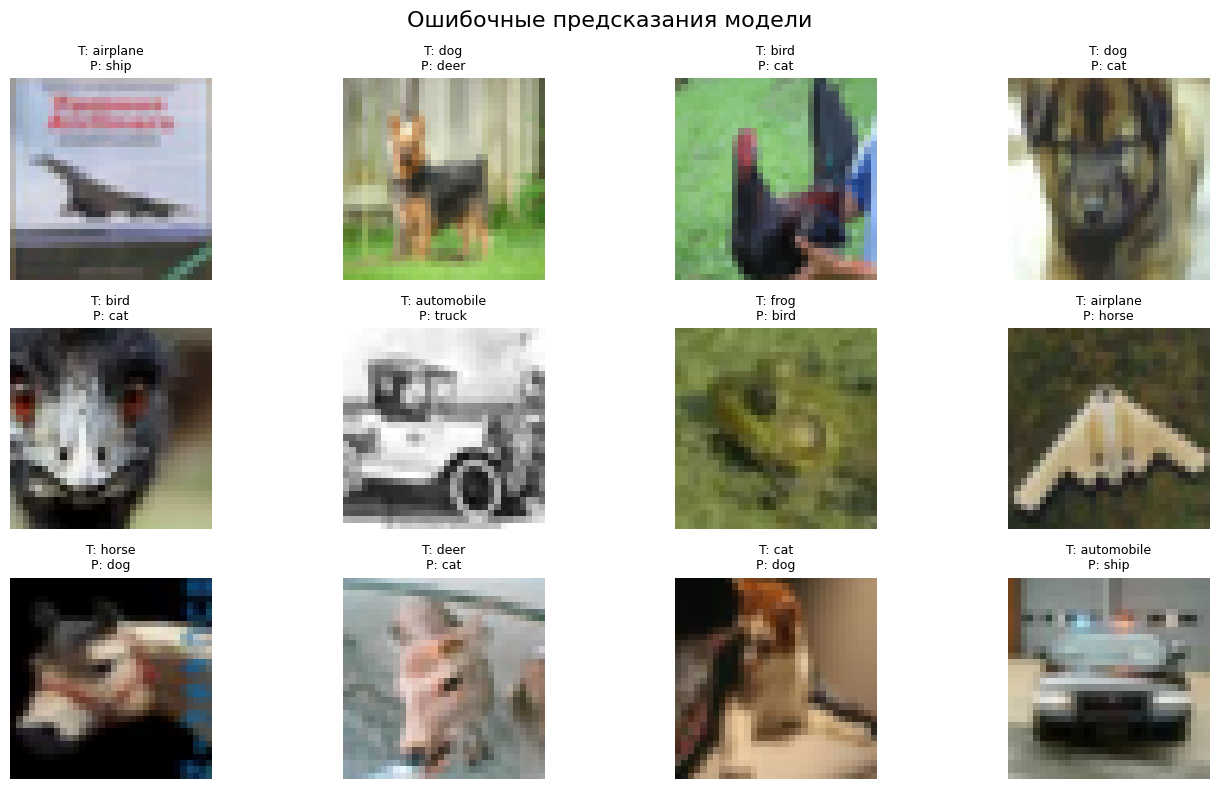

In [96]:
@torch.no_grad()
def show_misclassified(model, loader, class_names, device, n=12):
    model.eval()
    wrong_images = []
    wrong_true = []
    wrong_pred = []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        preds = torch.argmax(logits, dim=1)

        wrong_mask = preds != y
        if wrong_mask.any():
            wrong_images.extend(x[wrong_mask].cpu())
            wrong_true.extend(y[wrong_mask].cpu().numpy())
            wrong_pred.extend(preds[wrong_mask].cpu().numpy())

        if len(wrong_images) >= n:
            break

    n = min(n, len(wrong_images))
    plt.figure(figsize=(14, 8))
    for i in range(n):
        ax = plt.subplot(3, 4, i + 1)
        img = denormalize(wrong_images[i]).clamp(0, 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.title(f"T: {class_names[wrong_true[i]]}\nP: {class_names[wrong_pred[i]]}", fontsize=9)
        plt.axis("off")
    plt.suptitle("Ошибочные предсказания модели", fontsize=16)
    plt.tight_layout()
    plt.show()

show_misclassified(best_model, test_loader, class_names, device, n=12)

Какие классы путаются чаще всего

In [97]:
cm = confusion_matrix(targets, preds)
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

# Ищем самую большую ошибочную пару
i, j = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)

print(f"Чаще всего модель путает: {class_names[i]} -> {class_names[j]}")
print(f"Количество таких ошибок: {cm_no_diag[i, j]}")

Чаще всего модель путает: cat -> dog
Количество таких ошибок: 153
